# RQ3 Analysis: BERTScore (Semantic Similarity)

Compares the semantic similarity of human-written vs. LLM-generated PR descriptions using BERTScore.

- Uses the `bert-score` Python package with the `microsoft/deberta-xlarge-mnli` model.
- `rescale_with_baseline=True` for normalized 0.0–1.0 scores.
- Uses `BERTScorer` to cache the model in memory for efficient batch processing.
- Focus on the **F1-Score** as the primary similarity measure.
- Each AI-generated text is compared against its **paired human text** (same `pr_id`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp
import torch
from bert_score import BERTScorer

In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '/mnt/ext-hdd1/ayo/llm-in-prs/phase3/datasets/temperature_1/run_3_corrected_detection_v1/corpus.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

In [8]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['Qwen/Qwen2.5-72B-Instruct' 'gpt-5-mini-2025-08-07'
 'meta-llama/llama-3.1-70b-instruct']
Human entries: 308, AI entries: 5322


## 2. Compute BERTScore

For each AI-generated text, we compare it against its paired human-written text (same `pr_id`) using BERTScore F1.
We use `BERTScorer` with model caching for efficient batch processing of N=5,322 comparisons.

In [9]:
# Build a lookup: pr_id -> human text
human_text_lookup = dict(zip(human_df['normalized_pr_id'], human_df['text'].astype(str)))

In [10]:
# Prepare reference and candidate lists for BERTScore batch computation
candidates = []  # AI-generated texts
references = []  # Corresponding human texts

for _, row in ai_df.iterrows():
    ai_text = str(row['text']) if pd.notna(row['text']) else ''
    human_text = human_text_lookup.get(row['normalized_pr_id'], '')
    candidates.append(ai_text)
    references.append(human_text)

print(f"Total comparisons to compute: {len(candidates)}")

Total comparisons to compute: 5322


In [11]:
import os
from pathlib import Path

# The rerun is offline and pinned to the exact cached DeBERTa snapshot recorded by the launcher.
os.environ['PYTORCH_MPS_HIGH_WATERMARK_RATIO'] = '0.0'

if torch.backends.mps.is_available():
    device = 'mps'
elif torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'
print(f"Using device: {device}")

BATCH_SIZE = 8
SAFE_MAX_LENGTH = 512
MODEL_NAME = 'microsoft/deberta-xlarge-mnli'
MODEL_REVISION = os.environ['RQ23_DEBERTA_REVISION']
MODEL_SNAPSHOT = Path(os.environ['RQ23_DEBERTA_SNAPSHOT']).resolve()
BASELINE_PATH = Path(os.environ['RQ23_BERTSCORE_BASELINE']).resolve()

if MODEL_REVISION != '5b07a9086c1dbb79981ff7b05b4d1ad83b3af51c':
    raise RuntimeError(f'Unexpected DeBERTa revision: {MODEL_REVISION}')
if not (MODEL_SNAPSHOT / 'config.json').is_file():
    raise RuntimeError(f'Missing pinned DeBERTa snapshot: {MODEL_SNAPSHOT}')
if not BASELINE_PATH.is_file():
    raise RuntimeError(f'Missing BERTScore rescaling baseline: {BASELINE_PATH}')

scorer = BERTScorer(
    model_type=str(MODEL_SNAPSHOT),
    num_layers=40,
    rescale_with_baseline=True,
    baseline_path=str(BASELINE_PATH),
    lang='en',
    device=device,
    batch_size=BATCH_SIZE,
)
tokenizer_max_len = getattr(scorer._tokenizer, 'model_max_length', SAFE_MAX_LENGTH)
if tokenizer_max_len is None or int(tokenizer_max_len) > 1_000_000:
    scorer._tokenizer.model_max_length = SAFE_MAX_LENGTH
else:
    scorer._tokenizer.model_max_length = min(int(tokenizer_max_len), SAFE_MAX_LENGTH)

print(
    f"BERTScorer initialized (model={MODEL_NAME}, revision={MODEL_REVISION}, "
    f"device={device}, batch_size={BATCH_SIZE}, "
    f"tokenizer_max_length={scorer._tokenizer.model_max_length})."
)


Using device: cuda


Loading weights:   0%|          | 0/772 [00:00<?, ?it/s]

DebertaModel LOAD REPORT from: /home/ayo-b/.cache/huggingface/hub/models--microsoft--deberta-xlarge-mnli/snapshots/5b07a9086c1dbb79981ff7b05b4d1ad83b3af51c
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
classifier.bias     | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 
classifier.weight   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERTScorer initialized (model=microsoft/deberta-xlarge-mnli, revision=5b07a9086c1dbb79981ff7b05b4d1ad83b3af51c, device=cuda, batch_size=8, tokenizer_max_length=512).


In [12]:
# Compute BERTScore in chunks with gradient tracking disabled
# Small chunks to avoid MPS/GPU memory exhaustion with large models
CHUNK_SIZE = 128
all_f1_scores = []
total = len(candidates)

print(f"Processing {total} comparisons in chunks of {CHUNK_SIZE} (batch_size={BATCH_SIZE})...")

with torch.no_grad():
    for start_idx in range(0, total, CHUNK_SIZE):
        end_idx = min(start_idx + CHUNK_SIZE, total)
        chunk_cands = candidates[start_idx:end_idx]
        chunk_refs = references[start_idx:end_idx]

        try:
            P, R, F1 = scorer.score(chunk_cands, chunk_refs)
        except OverflowError:
            # Defensive fallback for tokenizer max_length overflow in fast tokenizers
            scorer._tokenizer.model_max_length = 512
            P, R, F1 = scorer.score(chunk_cands, chunk_refs)

        all_f1_scores.extend(F1.cpu().numpy().tolist())

        # Free MPS/CUDA memory between chunks
        if device == 'mps':
            torch.mps.empty_cache()
        elif device == 'cuda':
            torch.cuda.empty_cache()

        print(f"  Processed {end_idx}/{total} ({end_idx*100//total}%)")

# Store F1 scores in the AI dataframe
ai_df['bertscore_f1'] = all_f1_scores

print(f"\nBERTScore computation complete.")
print(f"F1 score range: [{ai_df['bertscore_f1'].min():.4f}, {ai_df['bertscore_f1'].max():.4f}]")
print(f"Mean F1: {ai_df['bertscore_f1'].mean():.4f}")

Processing 5322 comparisons in chunks of 128 (batch_size=8)...


  Processed 128/5322 (2%)


  Processed 256/5322 (4%)


  Processed 384/5322 (7%)


  Processed 512/5322 (9%)


  Processed 640/5322 (12%)


... (33 outputs left out)

  Processed 4992/5322 (93%)


  Processed 5120/5322 (96%)


  Processed 5248/5322 (98%)


  Processed 5322/5322 (100%)

BERTScore computation complete.
F1 score range: [-0.5566, 0.4925]
Mean F1: -0.0644


In [13]:
print("BERTScore F1 metrics computed.")
print(f"AI dataset size with BERTScore: {len(ai_df)}")
display(ai_df[['entry_type', 'model', 'normalized_pr_id', 'bertscore_f1']].head(10))

BERTScore F1 metrics computed.
AI dataset size with BERTScore: 5322


,entry_type,model,normalized_pr_id,bertscore_f1
0,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA0Njk3NjM5,-0.063703
1,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA0Njk3NjM5,-0.187686
2,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA0Njk3NjM5,-0.110915
3,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA0Njk3NjM5,-0.185210
4,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA0Njk3NjM5,-0.151294
5,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA0Njk3NjM5,-0.126910
6,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA1MzgxNDY1,-0.045852
7,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA1MzgxNDY1,-0.133469
8,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA1MzgxNDY1,-0.095595
9,ai,Qwen/Qwen2.5-72B-Instruct,MDExOlB1bGxSZXF1ZXN0MTA1MzgxNDY1,-0.088062


In [14]:
# Truncation diagnostics for Threats to Validity (BERTScore input length limit)
max_len = int(getattr(scorer._tokenizer, 'model_max_length', 512))
tok = scorer._tokenizer

def token_len(text: str) -> int:
    text = '' if pd.isna(text) else str(text)
    return len(tok.encode(text, add_special_tokens=True, truncation=False))

diag_df = ai_df[['normalized_pr_id', 'model', 'Context_Name', 'text']].copy()
diag_df = diag_df.rename(columns={'text': 'ai_text'})
diag_df['human_text'] = diag_df['normalized_pr_id'].map(human_text_lookup).fillna('')

diag_df['ai_tokens'] = diag_df['ai_text'].map(token_len)
diag_df['human_tokens'] = diag_df['human_text'].map(token_len)

diag_df['ai_truncated'] = diag_df['ai_tokens'] > max_len
diag_df['human_truncated'] = diag_df['human_tokens'] > max_len
diag_df['pair_any_truncated'] = diag_df['ai_truncated'] | diag_df['human_truncated']

# How much was truncated (tokens beyond model max length)
diag_df['ai_excess_tokens'] = (diag_df['ai_tokens'] - max_len).clip(lower=0)
diag_df['human_excess_tokens'] = (diag_df['human_tokens'] - max_len).clip(lower=0)
diag_df['pair_excess_tokens'] = diag_df['ai_excess_tokens'] + diag_df['human_excess_tokens']

# Token totals (for proportional loss estimates)
diag_df['ai_total_tokens'] = diag_df['ai_tokens']
diag_df['human_total_tokens'] = diag_df['human_tokens']
diag_df['pair_total_tokens'] = diag_df['ai_tokens'] + diag_df['human_tokens']

trunc_summary = (
    diag_df.groupby(['model', 'Context_Name'], as_index=False)
    .agg(
        N=('normalized_pr_id', 'size'),
        AI_truncated_n=('ai_truncated', 'sum'),
        Human_truncated_n=('human_truncated', 'sum'),
        Pair_any_truncated_n=('pair_any_truncated', 'sum'),
        AI_excess_total_tokens=('ai_excess_tokens', 'sum'),
        Human_excess_total_tokens=('human_excess_tokens', 'sum'),
        Pair_excess_total_tokens=('pair_excess_tokens', 'sum'),
        AI_total_tokens=('ai_total_tokens', 'sum'),
        Human_total_tokens=('human_total_tokens', 'sum'),
        Pair_total_tokens=('pair_total_tokens', 'sum')
    )
)

trunc_summary['AI_trunc_rate_%'] = (100 * trunc_summary['AI_truncated_n'] / trunc_summary['N']).round(2)
trunc_summary['Human_trunc_rate_%'] = (100 * trunc_summary['Human_truncated_n'] / trunc_summary['N']).round(2)
trunc_summary['Pair_any_trunc_rate_%'] = (100 * trunc_summary['Pair_any_truncated_n'] / trunc_summary['N']).round(2)

# Mean excess tokens among truncated items only
trunc_summary['AI_excess_mean_tokens_if_truncated'] = np.where(
    trunc_summary['AI_truncated_n'] > 0,
    (trunc_summary['AI_excess_total_tokens'] / trunc_summary['AI_truncated_n']).round(2),
    0.0
)
trunc_summary['Human_excess_mean_tokens_if_truncated'] = np.where(
    trunc_summary['Human_truncated_n'] > 0,
    (trunc_summary['Human_excess_total_tokens'] / trunc_summary['Human_truncated_n']).round(2),
    0.0
)

# Proportion of tokens removed (excess / total)
trunc_summary['AI_token_loss_%'] = np.where(
    trunc_summary['AI_total_tokens'] > 0,
    (100 * trunc_summary['AI_excess_total_tokens'] / trunc_summary['AI_total_tokens']).round(2),
    0.0
)
trunc_summary['Human_token_loss_%'] = np.where(
    trunc_summary['Human_total_tokens'] > 0,
    (100 * trunc_summary['Human_excess_total_tokens'] / trunc_summary['Human_total_tokens']).round(2),
    0.0
)
trunc_summary['Pair_token_loss_%'] = np.where(
    trunc_summary['Pair_total_tokens'] > 0,
    (100 * trunc_summary['Pair_excess_total_tokens'] / trunc_summary['Pair_total_tokens']).round(2),
    0.0
)

trunc_summary = trunc_summary.sort_values(['model', 'Context_Name']).reset_index(drop=True)

display_cols = [
    'model', 'Context_Name', 'N',
    'AI_trunc_rate_%', 'Human_trunc_rate_%', 'Pair_any_trunc_rate_%',
    'AI_excess_total_tokens', 'Human_excess_total_tokens', 'Pair_excess_total_tokens',
    'AI_excess_mean_tokens_if_truncated', 'Human_excess_mean_tokens_if_truncated',
    'AI_token_loss_%', 'Human_token_loss_%', 'Pair_token_loss_%'
 ]
display(trunc_summary[display_cols])

# Overall detail
overall_n = len(diag_df)
overall_ai_rate = 100 * diag_df['ai_truncated'].mean()
overall_human_rate = 100 * diag_df['human_truncated'].mean()
overall_pair_rate = 100 * diag_df['pair_any_truncated'].mean()

overall_ai_excess = int(diag_df['ai_excess_tokens'].sum())
overall_human_excess = int(diag_df['human_excess_tokens'].sum())
overall_pair_excess = int(diag_df['pair_excess_tokens'].sum())

overall_ai_loss_pct = 100 * diag_df['ai_excess_tokens'].sum() / max(diag_df['ai_tokens'].sum(), 1)
overall_human_loss_pct = 100 * diag_df['human_excess_tokens'].sum() / max(diag_df['human_tokens'].sum(), 1)
overall_pair_loss_pct = 100 * diag_df['pair_excess_tokens'].sum() / max((diag_df['ai_tokens'] + diag_df['human_tokens']).sum(), 1)

max_pair_row = trunc_summary.loc[trunc_summary['Pair_any_trunc_rate_%'].idxmax()]
max_excess_row = trunc_summary.loc[trunc_summary['Pair_excess_total_tokens'].idxmax()]

validity_note = (
    f"Threats to validity — BERTScore truncation: We computed BERTScore using "
    f"{getattr(scorer, 'model_type', 'microsoft/deberta-xlarge-mnli')} with a tokenizer limit of {max_len} tokens. "
    f"Texts longer than this limit were truncated before scoring. Across N={overall_n} AI–human pairs, "
    f"truncation affected {overall_pair_rate:.2f}% of pairs (AI side: {overall_ai_rate:.2f}%, "
    f"human side: {overall_human_rate:.2f}%). In total, truncation removed {overall_pair_excess:,} tokens "
    f"from pair inputs ({overall_pair_loss_pct:.2f}% token loss; AI={overall_ai_excess:,}/{overall_ai_loss_pct:.2f}%, "
    f"Human={overall_human_excess:,}/{overall_human_loss_pct:.2f}%). The highest pair-level truncation rate was "
    f"{max_pair_row['Pair_any_trunc_rate_%']:.2f}% for model={max_pair_row['model']} under context="
    f"{max_pair_row['Context_Name']}, while the largest token removal volume was "
    f"{int(max_excess_row['Pair_excess_total_tokens']):,} tokens for model={max_excess_row['model']} under context="
    f"{max_excess_row['Context_Name']}. Therefore, BERTScore values for long descriptions may under-represent "
    f"content appearing beyond the first {max_len} tokens."
 )

print('\nReady-to-paste validity note:\n')
print(validity_note)

# Optional export for manuscript artifacts
import os
os.makedirs('outputs', exist_ok=True)
trunc_summary.to_csv('outputs/rq3_bertscore_truncation_summary.csv', index=False)
with open('outputs/rq3_bertscore_validity_note.txt', 'w', encoding='utf-8') as f:
    f.write(validity_note + '\n')
print("\nSaved: outputs/rq3_bertscore_truncation_summary.csv")
print("Saved: outputs/rq3_bertscore_validity_note.txt")

Token indices sequence length is longer than the specified maximum sequence length for this model (1877 > 512). Running this sequence through the model will result in indexing errors


,model,Context_Name,N,AI_trunc_rate_%,Human_trunc_rate_%,Pair_any_trunc_rate_%,AI_excess_total_tokens,Human_excess_total_tokens,Pair_excess_total_tokens,AI_excess_mean_tokens_if_truncated,Human_excess_mean_tokens_if_truncated,AI_token_loss_%,Human_token_loss_%,Pair_token_loss_%
0,Qwen/Qwen2.5-72B-Instruct,File Contents,302,0.33,5.30,5.63,1365,1594,2959,1365.00,99.62,3.34,2.14,2.56
1,Qwen/Qwen2.5-72B-Instruct,File Diff,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.48
2,Qwen/Qwen2.5-72B-Instruct,Linked Issue,273,0.00,5.86,5.86,0,1594,1594,0.00,99.62,0.00,2.36,1.71
3,Qwen/Qwen2.5-72B-Instruct,PR Title,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.75
4,Qwen/Qwen2.5-72B-Instruct,Repo Path,308,0.00,5.19,5.19,0,1594,1594,0.00,99.62,0.00,2.12,1.58
5,Qwen/Qwen2.5-72B-Instruct,Without File Contents,273,0.00,5.86,5.86,0,1594,1594,0.00,99.62,0.00,2.36,1.58
6,gpt-5-mini-2025-08-07,File Contents,302,23.51,5.30,26.82,10459,1594,12053,147.31,99.62,8.94,2.14,6.29
7,gpt-5-mini-2025-08-07,File Diff,308,12.01,5.19,16.56,4931,1594,6525,133.27,99.62,5.32,2.12,3.89
8,gpt-5-mini-2025-08-07,Linked Issue,273,21.98,5.86,26.01,7106,1594,8700,118.43,99.62,6.21,2.36,4.78
9,gpt-5-mini-2025-08-07,PR Title,308,3.25,5.19,8.44,524,1594,2118,52.40,99.62,0.59,2.12,1.29



Ready-to-paste validity note:

Threats to validity — BERTScore truncation: We computed BERTScore using /home/ayo-b/.cache/huggingface/hub/models--microsoft--deberta-xlarge-mnli/snapshots/5b07a9086c1dbb79981ff7b05b4d1ad83b3af51c with a tokenizer limit of 512 tokens. Texts longer than this limit were truncated before scoring. Across N=5322 AI–human pairs, truncation affected 9.88% of pairs (AI side: 4.85%, human side: 5.41%). In total, truncation removed 64,066 tokens from pair inputs (2.94% token loss; AI=35,374/4.05%, Human=28,692/2.20%). The highest pair-level truncation rate was 26.82% for model=gpt-5-mini-2025-08-07 under context=File Contents, while the largest token removal volume was 12,053 tokens for model=gpt-5-mini-2025-08-07 under context=File Contents. Therefore, BERTScore values for long descriptions may under-represent content appearing beyond the first 512 tokens.

Saved: outputs/rq3_bertscore_truncation_summary.csv
Saved: outputs/rq3_bertscore_validity_note.txt


## 3. BERTScore F1 Boxplots by Context per LLM

This mirrors the plotting design used in the BM25 and ROUGE notebooks:

- One panel per LLM model (stacked vertically).
- Each panel includes the 6 AI context boxplots.
- No Human boxplot is included in this view.

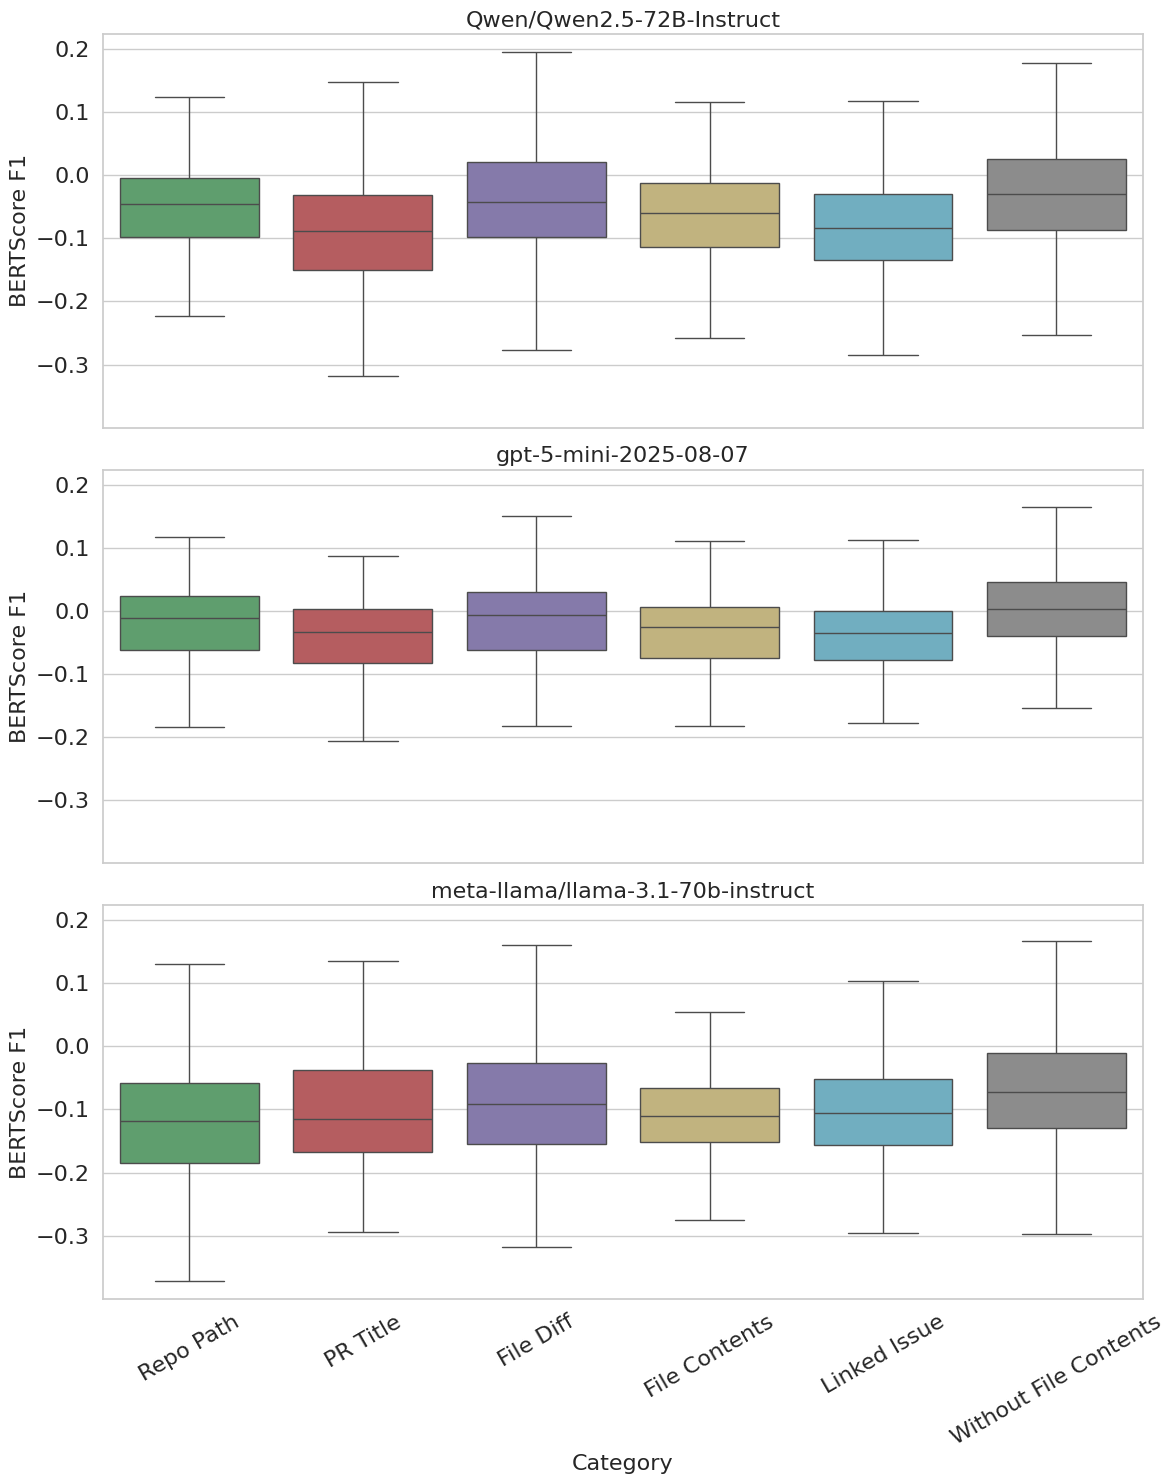

In [15]:
context_order = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = context_order
palette_map = {
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=16)

    panel_df = ai_df[ai_df['model'] == model][['bertscore_f1', 'Context_Name']].dropna().copy()
    panel_df['Category'] = panel_df['Context_Name']

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='bertscore_f1',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
    ax.set_ylabel('BERTScore F1', fontsize=16)
    ax.tick_params(axis='x', rotation=30, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'bertscore.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 3. Final RQ3 Answer: Human Baseline Comparison

This section directly answers the core RQ3 objective using paired AI↔Human BERTScore results.

- **Reference**: Original human-written PR descriptions (`n=308`, paired PR set).
- **Candidates**: AI descriptions for each model and context (P-1 ... P-6).
- **Reported**: Mean/Median F1 per [Model, Context], Cliff's δ vs Human Baseline (reported but non-discriminative here), and ranking by highest AI Median F1.

In [16]:
# Corrected generated-to-reference summary; human self-comparisons are not a baseline.
import hashlib
import json
from pathlib import Path
import bert_score

row_dir = Path('outputs/row_level')
row_dir.mkdir(parents=True, exist_ok=True)
row_cols = ['normalized_pr_id', 'entry_type', 'model', 'variation', 'Context_Name', 'bertscore_f1']
row_scores = ai_df[row_cols].sort_values(
    ['model', 'variation', 'normalized_pr_id'], kind='stable'
)
row_scores.to_csv(row_dir / 'bertscore_metrics.csv', index=False)

summary = (
    row_scores.groupby(['model', 'variation', 'Context_Name'], as_index=False)
    .agg(n=('normalized_pr_id', 'size'), mean=('bertscore_f1', 'mean'), median=('bertscore_f1', 'median'))
    .rename(columns={'Context_Name': 'context'})
    .sort_values(['model', 'variation'], kind='stable')
)
best = (
    summary.sort_values(['model', 'median', 'mean'], ascending=[True, False, False], kind='stable')
    .groupby('model', as_index=False)
    .first()
)
summary.to_csv('outputs/rq2_bertscore_generated_to_reference_summary.csv', index=False)
best.to_csv('outputs/rq2_bertscore_best_context.csv', index=False)

baseline_sha = hashlib.sha256(BASELINE_PATH.read_bytes()).hexdigest()
metadata_dir = Path('outputs/model_metadata')
metadata_dir.mkdir(parents=True, exist_ok=True)
(metadata_dir / 'bertscore.json').write_text(
    json.dumps({
        'bert_score_version': bert_score.__version__,
        'model_name': MODEL_NAME,
        'model_revision': MODEL_REVISION,
        'model_snapshot': str(MODEL_SNAPSHOT),
        'num_layers': 40,
        'rescale_with_baseline': True,
        'baseline_path': str(BASELINE_PATH),
        'baseline_sha256': baseline_sha,
        'max_length': SAFE_MAX_LENGTH,
        'batch_size': BATCH_SIZE,
    }, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)
display(summary)
display(best)
print('Saved generated-to-reference BERTScore summaries without a human-self baseline.')


,model,variation,context,n,mean,median
0,Qwen/Qwen2.5-72B-Instruct,P-1,Repo Path,308,-0.052190,-0.044987
1,Qwen/Qwen2.5-72B-Instruct,P-2,PR Title,308,-0.085502,-0.088302
2,Qwen/Qwen2.5-72B-Instruct,P-3,File Diff,308,-0.039284,-0.041797
3,Qwen/Qwen2.5-72B-Instruct,P-4,File Contents,302,-0.068960,-0.059740
4,Qwen/Qwen2.5-72B-Instruct,P-5,Linked Issue,273,-0.084036,-0.084023
5,Qwen/Qwen2.5-72B-Instruct,P-6,Without File Contents,273,-0.031009,-0.029448
6,gpt-5-mini-2025-08-07,P-1,Repo Path,308,-0.036238,-0.011181
7,gpt-5-mini-2025-08-07,P-2,PR Title,308,-0.053414,-0.032672
8,gpt-5-mini-2025-08-07,P-3,File Diff,308,-0.023854,-0.005766
9,gpt-5-mini-2025-08-07,P-4,File Contents,302,-0.047706,-0.024846


,model,variation,context,n,mean,median
0,Qwen/Qwen2.5-72B-Instruct,P-6,Without File Contents,273,-0.031009,-0.029448
1,gpt-5-mini-2025-08-07,P-6,Without File Contents,273,-0.016410,0.002550
2,meta-llama/llama-3.1-70b-instruct,P-6,Without File Contents,273,-0.058679,-0.071554


Saved generated-to-reference BERTScore summaries without a human-self baseline.
